# Спринт 2 - Проект модуля - нейросеть для автодополнения текстов

## Инициалиация

In [41]:
import random
import pandas as pd
import numpy as np
import pathlib as path
import torch

SEED = 43

# пути
PREPROCESSING_PATH = path.Path('data/preprocessing')
PREPROCESSING_PATH.mkdir(parents=True, exist_ok=True)

MODELS_PATH = path.Path('data/models')
MODELS_PATH.mkdir(parents=True, exist_ok=True)

def init_random():
    """
    Инициализация случайных величин для повторяемости экспериментов
    """   
    torch.random.manual_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)


## Этап 0 - подготовка
см. [readme.md](readme.md) для установки python и зависимостей

## Этап 1 - загрузка и подготовка данных

1. Загрузить датасет WikiText-2.
2. Провести разведочный анализ: посмотреть примеры текстов, посчитать статистики (число предложений, среднюю длину, распределение длин).
3. Реализовать пословную токенизацию: построить словарь на обучающей выборке с порогом по частоте.
4. Сформировать последовательности фиксированной длины для обучения.
5. Создать `torch.Dataset` и `DataLoader`.

### Загрузка датасета

In [42]:
# загрузка датасета

from datasets import load_dataset

wiki_ds = load_dataset('wikitext', 'wikitext-2-raw-v1')
wiki_ds

Using the latest cached version of the dataset since wikitext couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'wikitext-2-raw-v1' at d:\AI_tools\huggingface\datasets\wikitext\wikitext-2-raw-v1\0.0.0\b08601e04326c79dfdd32d625aee71d232d685c3 (last modified on Tue Oct 13 17:18:06 2026).


DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})

### Cодержимое текстов

In [43]:
# посмотрим на содержимое - поле [text]

tokens = wiki_ds['train']['text']
print(f'train texts size = {len(tokens)}')

print('content of first 5 texts:')
for i,text in enumerate(tokens[0:5]):
    print(f'{i}: size = {len(text)}, text: [{text}]')

train texts size = 36718
content of first 5 texts:
0: size = 0, text: []
1: size = 30, text: [ = Valkyria Chronicles III = 
]
2: size = 0, text: []
3: size = 706, text: [ Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " . 
]
4: size = 524, text: [ The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chr

### Распределение длины текста

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.axes import Axes

def calc_stats_for_ds(texts, ds_title, ax: Axes):
    """
    Подсчет и вывод статистики по длине текста:
    - всего (total) 
    - не пустые (non zero)
    - среднее (average)
    - медиана (median)
    - 5% перцентиль (5% percentile)
    - 95% перцентиль (95% percentile)

    Args
    --
    texts: list 
        список текстов из датасетов
    ds_title: string 
        название датасета
    ax: Axes 
        axes для выпода графика    

    """
    print(f'Stats for dataset = {ds_title}')

    text_len = [len(text) for text in texts]
    print(f'    total = {len(text_len)}')
    print(f'    non zero = {np.count_nonzero(text_len)}')
    print(f'    average = {np.average(text_len):.2f}')
    print(f'    median = {np.median(text_len)}')
    print(f'    5% percentile = {np.percentile(text_len, 5)}')
    print(f'    95% percentile = {np.percentile(text_len, 95)}')

    ax.hist(text_len, bins=20)
    ax.set_xlabel('text length');
    ax.legend([ds_title])
    ax.set_title(f'{ds_title} - text length histogram');
    ax.grid(True)    


Stats for dataset = train
    total = 36718
    non zero = 23767
    average = 296.67
    median = 33.0
    5% percentile = 0.0
    95% percentile = 1135.0
Stats for dataset = validation
    total = 3760
    non zero = 2461
    average = 303.76
    median = 36.0
    5% percentile = 0.0
    95% percentile = 1138.0999999999995
Stats for dataset = test
    total = 4358
    non zero = 2891
    average = 295.00
    median = 35.0
    5% percentile = 0.0
    95% percentile = 1128.2999999999993


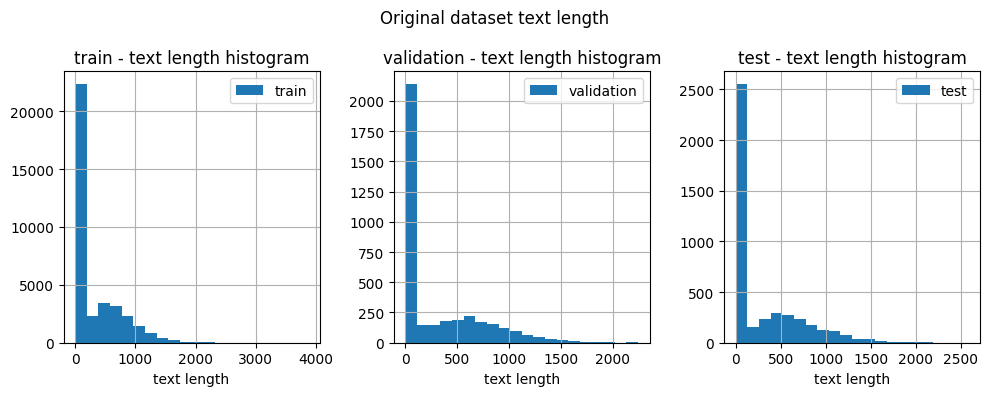

In [45]:
# посчитаем распределение длины текста

fig, axs = plt.subplots(1,3,figsize=(10,4))
for i, ds_name in enumerate(['train', 'validation', 'test']):
    calc_stats_for_ds(wiki_ds[ds_name]['text'], ds_name, axs[i])

plt.suptitle('Original dataset text length')
plt.tight_layout()
plt.show()

Видим, что почти 1/3 датасета содержит строки нулевого размера
Отфильтруем их и посмотрим на те, которые не нулевые

### Распределение длины текста после фильтра пустых строк

In [46]:
def filter_zero_length_text(text_ds):
    """
    Фильтрует тексты нулевого размера.

    Args
    --
        text_ds: dict - словарь с текстами (с ключом `text`)
    
    Return
    --
        list[str]: очищенный список текстов
    
    """
    nonzero_texts = [text for text in text_ds['text'] if len(text) != 0]
    return nonzero_texts


Stats for dataset = train
    total = 23767
    non zero = 23767
    average = 458.32
    median = 401.0
    5% percentile = 19.0
    95% percentile = 1258.0
Stats for dataset = validation
    total = 2461
    non zero = 2461
    average = 464.10
    median = 404.0
    5% percentile = 20.0
    95% percentile = 1250.0
Stats for dataset = test
    total = 2891
    non zero = 2891
    average = 444.70
    median = 375.0
    5% percentile = 18.0
    95% percentile = 1253.5


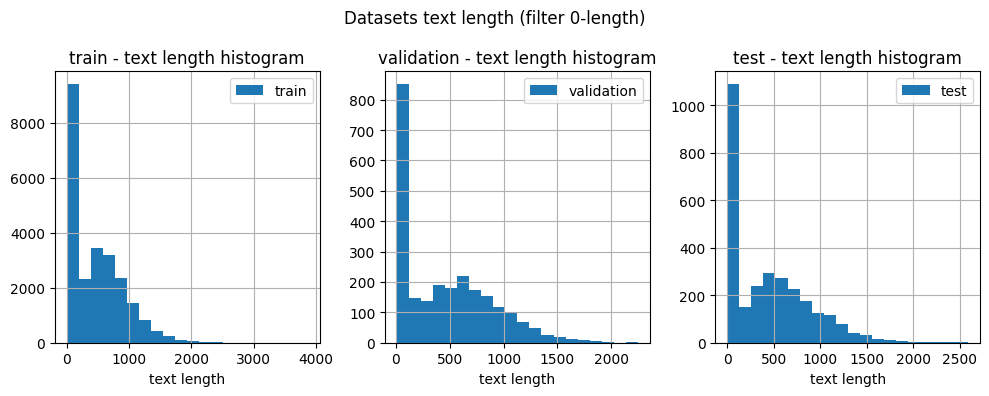

In [47]:
# посчитаем среднюю длину текста, кроме 0-длины

import numpy as np
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1,3,figsize=(10,4))
for i, ds_name in enumerate(['train', 'validation', 'test']):
    nonzero_texts = filter_zero_length_text(wiki_ds[ds_name])
    calc_stats_for_ds(nonzero_texts, ds_name, axs[i])

plt.suptitle('Datasets text length (filter 0-length)')
plt.tight_layout()
plt.show()

Дополнительно рассмотрим короткие тексты до 100 слов

Stats for dataset = train
    total = 8454
    non zero = 8454
    average = 32.84
    median = 28.0
    5% percentile = 16.0
    95% percentile = 72.0
Stats for dataset = validation
    total = 812
    non zero = 812
    average = 32.94
    median = 29.0
    5% percentile = 17.0
    95% percentile = 67.44999999999993
Stats for dataset = test
    total = 1056
    non zero = 1056
    average = 32.61
    median = 29.0
    5% percentile = 14.0
    95% percentile = 69.0


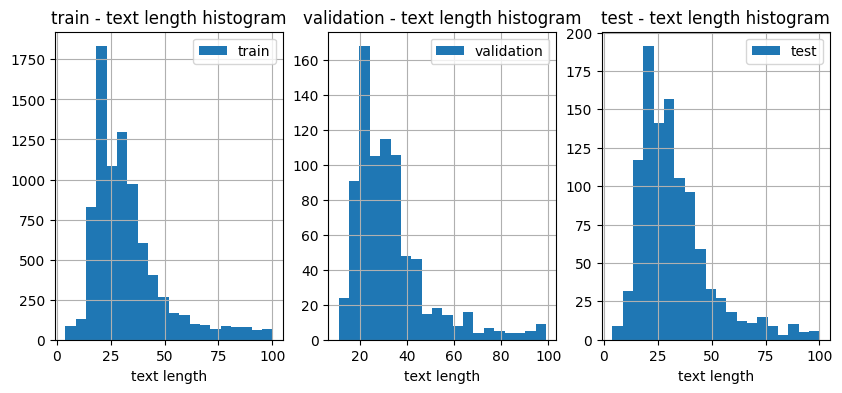

In [48]:

fig, axs = plt.subplots(1,3,figsize=(10,4))
for i, ds_name in enumerate(['train', 'validation', 'test']):
    text_short = [text for text in wiki_ds[ds_name]['text'] if len(text) > 0 and len(text) <= 100]
    calc_stats_for_ds(text_short, ds_name, axs[i])
    

Итого - средняя (медиана) длины текста:
- train = 401.0
- validation = 404.0
- test = 375.0

### Очищенный датасет (от пустых строк)
- преобразуем в pandas.Dataframe 
- сохраним в csv

In [49]:
import pandas as pd

stages = ['train', 'validation', 'test']
data = {'stage': stages, 'texts': []}

# фильтрация пустых строк
for ds_name in stages:
    text_clean = filter_zero_length_text(wiki_ds[ds_name])
    data['texts'].append(text_clean)

wiki_df = pd.DataFrame(data)
wiki_df = wiki_df.explode('texts').reset_index(drop=True)

# save to file
wiki_df.to_csv(PREPROCESSING_PATH/'dataset.csv', index=False)

wiki_df

,stage,texts
0,train,= Valkyria Chronicles III = \n
1,train,Senjō no Valkyria 3 : Unrecorded Chronicles (...
2,train,"The game began development in 2010 , carrying..."
3,train,"It met with positive sales in Japan , and was..."
4,train,= = Gameplay = = \n
...,...,...
29114,test,AFI 's 10 Top 10 - # 6 Sports Film \n
29115,test,= = Legacy = = \n
29116,test,"In the decades since its release , The Hustle..."
29117,test,Paul Newman reprised his role as Fast Eddie F...


### Пословная токенизация для словаря на обучающей выборке
- проанализируем частоту появления слов в тексте 
- определим порог частоты для исключения редких слов, так чтобы не сильно сокращать исходный текст 

In [50]:
# функция очистки и подготовки текста

import re
def preprocess_text(text: str) -> str:
    """
    Предобработка текста перед токенизацией.
    - приведение к нижнему регистру
    - удаление спецсимволов
    - удаление дублирующихся пробелов и пробелах в конце или начале

    Return
    --
        text - очищенный текст    
    """

    # приведение к нижнему регистру
    text = text.lower()
    # удаление всех символов, кроме букв, чисел и пробелов
    text = re.sub(r'[^a-zа-яё0-9 ]+', '', text)
    # удаление дублирующихся пробелов и пробелов в начале и в конце
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

In [51]:
# загрузка из файла
import pandas as pd

wiki_df = pd.read_csv(PREPROCESSING_PATH / 'dataset.csv')
wiki_df

,stage,texts
0,train,= Valkyria Chronicles III = \n
1,train,Senjō no Valkyria 3 : Unrecorded Chronicles (...
2,train,"The game began development in 2010 , carrying..."
3,train,"It met with positive sales in Japan , and was..."
4,train,= = Gameplay = = \n
...,...,...
29114,test,AFI 's 10 Top 10 - # 6 Sports Film \n
29115,test,= = Legacy = = \n
29116,test,"In the decades since its release , The Hustle..."
29117,test,Paul Newman reprised his role as Fast Eddie F...


all_words size = 1,748,743
counter total words = 1,748,743, unique words count = 65,357
top 10 words:
    the  : 130,769   
    of   : 57,032    
    and  : 50,735    
    in   : 45,016    
    to   : 39,522    
    a    : 36,454    
    was  : 21,008    
    on   : 15,143    
    as   : 15,062    
    s    : 14,493    


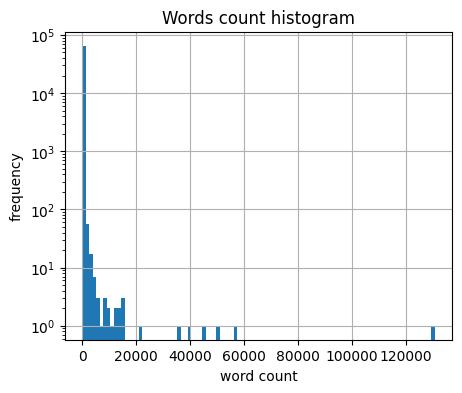

In [52]:
# счетчик слов для анализа частотности
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# формируем словарь из слов обучающей выборки
train_texts = wiki_df[wiki_df['stage'] == 'train']['texts']

# составим словарь всех слов на предобработанных текстах, исключая спецсимволы и пунктуацию
all_words = [word for text in train_texts for word in preprocess_text(text).split()]

print(f'all_words size = {len(all_words):,}')

counter = Counter(all_words)
print(f'counter total words = {counter.total():,}, unique words count = {len(counter):,}')
print(f'top 10 words:')
for w,c in counter.most_common(10): 
    print(f'    {w:5}: {c:<10,}')

# построим гистограмму частоты слов
word_freq = np.array(list(counter.values()))
plt.figure(figsize=(5,4))
plt.hist(word_freq, bins=100, log=True)
plt.xlabel('word count');plt.ylabel('frequency')
plt.title('Words count histogram')
plt.grid(True)

In [53]:
# определим порог частоты для фильтрации редких слов

freqs = np.array(list(counter.values()))
total = freqs.sum()

""" 
посмотрим какой объем занимают наименее частотные слова:
- min_freq - минимальная частота - сколько раз слово встречается во всем тексте (train - выборка)
- vocab - сколько слов в словаре с частотой, которая больше или равна порогу min_freq
- % vocab - относительная доля слов в словаре, с частотой, которая больше или равна порогу min_freq
- % tokens kept - какая доля слов сохраняется при исключении слов с минимальной частотой min_freq
- % tokens removed - какая доля слов удаляется при исключении слов с минимальной частотой min_freq
""" 

print(f"{'min_freq':>8} | {'vocab':>7} | {'% vocab':>7} | {'% tokens kept':>12} | {'% tokens removed':>8}")
for mf in [1, 2, 3, 5, 10, 20]:
    kept = freqs[freqs >= mf]
    print(f"{mf:>8} | {len(kept):>7,} | {len(kept)/len(freqs):>7.1%} | {kept.sum()/total:>13.2%} | {(total-kept.sum())/total:>8.2%}")

min_freq |   vocab | % vocab | % tokens kept | % tokens removed
       1 |  65,357 |  100.0% |       100.00% |    0.00%
       2 |  38,915 |   59.5% |        98.49% |    1.51%
       3 |  29,369 |   44.9% |        97.40% |    2.60%
       5 |  20,871 |   31.9% |        95.75% |    4.25%
      10 |  13,130 |   20.1% |        92.84% |    7.16%
      20 |   8,184 |   12.5% |        89.02% |   10.98%


Получается, что исключая слова с частотой менее 3-х (min_freq == 3):
- мы существенно сократим размер словаря - до 44.9%, что составит 29.369 слов (и уберем 65.357-29.369 = 35.988 редких слов), 
- при этом заменим (исключим) всего 2,57% слов (заменим их на специальный токен `<UNK>`)

То есть минимально повлияем на анализ смысла текстов, при существенном сокращении объема неинформативных данных - это должно упростить модель и позволить ей более эффективно учиться

### Фильтрация редких слов из словаря
- уберем редкие слова из словаря - те, чья частота менее 3-х раз во всем корпусе
- заменим в датасет исключаемые слова на специальный токен `<UNK>` для сохранения консистентности текстов

In [54]:
# отбор редких слов

import pandas as pd

rare_words = []
freq_threshold = 3
vocab = []

# отбор слов в словарь
for w,c in counter.items():
    if c < freq_threshold:
        rare_words.append(w)
    else:
        vocab.append(w)
        
print(f'rare_words size = {len(rare_words)}')
print(f'vocab size = {len(vocab)}')

# сохраним в файл
pd.DataFrame(rare_words, columns=['rare_word']).to_csv(PREPROCESSING_PATH / 'rare_words.csv', index=False)

# добавляем в словарь специальные слова для дальнейшей консистентности с датасетом
UNK_WORD = '<UNK>'
PAD_WORD = '<PAD>'
vocab.append(UNK_WORD)
vocab.append(PAD_WORD)

pd.DataFrame(vocab, columns=['word']).to_csv(PREPROCESSING_PATH / 'vocab.csv', index=False)

rare_words size = 35988
vocab size = 29369


#### Сохранение отфильтрованного датасета

In [ ]:
# заменим все редкие слова на специальный токен <UNK> во всех текстах датасета
# работает ~ 11 мин

import tqdm
import re

# токен замены
UNK_WORD = '<UNK>'

# компилируем регулярное выражение: только целые слова (по границам слов)
rare_words_pattern = re.compile(
    r'\b(?:' + '|'.join(re.escape(w) for w in rare_words) + r')\b'
)

def replace_rare_words(text: str) -> str:
    """
    Заменяет все редкие слова в тексте на токен <UNK>.

    Return
    --
        text - текст с замененными редкими словами
    """
    return rare_words_pattern.sub(UNK_WORD, text)

clean_df = wiki_df.copy()
BATCH = 500
n = clean_df.shape[0]

tokens = list(clean_df['texts'])

for start in tqdm.tqdm(range(0, n, 500), desc='texts'):
    end = min(start + BATCH, n) 
    idx = clean_df.index[start:end]

    # очищаем текст + применяем замену ко всем текстам
    tokens[start:end] = [replace_rare_words(preprocess_text(t)) for t in tokens[start:end]]

clean_df['texts'] = tokens 
clean_df['texts'] = clean_df['texts'].dropna()
clean_df = clean_df[clean_df['texts'].str.len() != 0] # убираем пустые строки после очистки

# сохраним обновленный датасет
clean_df.to_csv(PREPROCESSING_PATH / 'dataset_clean.csv', index=False)

clean_df

texts: 100%|██████████| 59/59 [11:34<00:00, 11.77s/it]


,stage,texts
0,train,valkyria chronicles iii
1,train,senj no valkyria 3 unrecorded chronicles japan...
2,train,the game began development in 2010 carrying ov...
3,train,it met with positive sales in japan and was pr...
4,train,gameplay
...,...,...
29114,test,<UNK> s 10 top 10 6 sports film
29115,test,legacy
29116,test,in the decades since its release the hustler h...
29117,test,paul newman reprised his role as fast eddie fe...


Проверка, что замена выполнена

In [56]:
# set для быстрой проверки принадлежности слова к редким
rare_words_set = set(rare_words)

# проверим, что редких слов больше не осталось
train_texts = clean_df[clean_df['stage'] == 'train']['texts']

# количество текстов, все еще содержащих редкие слова (без учета токена <UNK>)
contains_rare = train_texts.apply(
    lambda text: any(word in rare_words_set for word in text.split())
)
print(f'texts with rare words left = {contains_rare.sum():,}')

unk_count = train_texts.str.count(r"<UNK>").sum()
print(f'total <UNK> tokens in train = {unk_count:,}')

# ожидается доля <UNK> токенов ~ 2,6%: 
total_train_tokens = train_texts.str.split().apply(len).sum()
print(f'train tokens = {total_train_tokens:,}')
print(f'<UNK> share = {unk_count / total_train_tokens:.2%}')

texts with rare words left = 0
total <UNK> tokens in train = 45,534
train tokens = 1,748,743
<UNK> share = 2.60%


### Токенизатор для работы со словарем
- обернем подготовленный словарь (vocab) в токенизатор для удобства работы

In [57]:
import numpy as np
import pandas as pd

class WikiTextWordTokenizer():
    """
    Токенизатор для словаря  - превращает отсортированные уникальные слова в их индексы.
    Специальное слово `<UNK>` применяется для замены в случае отсутсвия слова в словаре (проблема-OOV).
    Специальное слово `<PAD>` используется для пэддинга коротких текстов при передаче в модель.
    Для спецслов зарезервированы индексы:
    - <PAD> - 0 - для совместимости с библиотекой torch (там по умолчанию 0 везде)
    - <UNK> - 1 - для удобства расположим тоже вначале

    """
    def __init__(self, word_vocab: list):
        print(f'WikiTextWordTokenizer __init__() word_vocab len = {len(word_vocab)}')

        self.UNK_WORD = '<UNK>'
        self.PAD_WORD = '<PAD>'
        self.PAD_TOKEN = 0 # this is `0` in other torch dataset operations
        self.UNK_TOKEN = 1 # 1 for simplicity

        # preserve order for unique words + special words to start of index
        unique_words = sorted(set(word_vocab) - {self.PAD_WORD, self.UNK_WORD})

        # use numpy to use array index search in conver_to_words()
        self.words = np.array([self.PAD_WORD, self.UNK_WORD] + unique_words)
        
        # map to tokens (which are indexes of words)
        self.word_to_idx = {w:idx for idx,w in enumerate(self.words)}
        
        print(f'words unique_words len = {len(unique_words)}, total len with specials = {len(self.words)}')
        print(f'word_to_idx total len = {len(self.word_to_idx)}')

        # check special tokens are on their place at the beginning
        assert self.word_to_idx[self.PAD_WORD] == self.PAD_TOKEN
        assert self.word_to_idx[self.UNK_WORD] == self.UNK_TOKEN
                
    def tokenize(self, words: list):
        # use map from pandas instead of for loop + handle unknown word (OOV-problem)
        return pd.Series(words).map(self.word_to_idx).fillna(self.UNK_TOKEN).astype('int32').tolist()

    def conver_to_words(self, tokens: list):
        return self.words[tokens]

#### test

test_vocab = ['a', 'b', 'c']
print(f'test_vocab: {test_vocab}')
tknz = WikiTextWordTokenizer(test_vocab)

test_words = ['a', 'c', 'a', 'X']
print(f'tokenize words = {test_words} to tokens => {tknz.tokenize(test_words)}')

test_tokens = [2, 4, 2, 1, 0]
print(f'convert tokens = {test_tokens} to words => {tknz.conver_to_words(test_tokens)}')
######

test_vocab: ['a', 'b', 'c']
WikiTextWordTokenizer __init__() word_vocab len = 3
words unique_words len = 3, total len with specials = 5
word_to_idx total len = 5
tokenize words = ['a', 'c', 'a', 'X'] to tokens => [2, 4, 2, 1]
convert tokens = [2, 4, 2, 1, 0] to words => ['a' 'c' 'a' '<UNK>' '<PAD>']


### Датасет для модели torch.Dataset
- сформируем обучающие последовательности в виде строк фиксированной длины до 32 символов
- подготовим torch.Dataset

In [58]:
def split_text_chunks(text: list|str, seq_len=32, overlap=16):
    """
    Разделение текста `text` на цепочки по `seq_len` слов с перекрытием скользящим окном размером `overlap` слов 
    (для перекрестного контекста между цепочками)    

    Args:
        text: list[str|int] | str
            исходный текст в виде последовательности (списка) слов (str) или токенов (int), 
            если подан текст целиком, то он предварительно разобьется на слова
        seq_len: int - требуемая длина цепочки на выход, 32 по умолчанию
        overlap: int - пересечение цепочек между собой, чтобы не разрывать границы смысла между цепочками, 16 по умолчанию
    
    Returns:
        chunks: list[str] - цепочки слов длиной `seq_len` или меньше если исходный текст короче, или для последнего окна

    """
    # если подан текст, то разобьем на слова
    if isinstance(text, str):
        text = text.split()

    chunks = []
    #print(f'begin text = {text}, seq_len = {seq_len}, overlap = {overlap}')
    
    # проверка, что параметры корректны
    if overlap >= seq_len or overlap < 1 or seq_len < 3:
        raise ValueError(f'wrong overlap and seq_len parameters - seq_len = {seq_len}, overlap = {overlap}')

    for i in range(0, len(text), overlap):
        start = i
        end = i + seq_len
        chunk = text[start:end]
        chunks.append(chunk) 

        if end >= len(text):
            break
       
    return chunks

#### test
a = [0,1,2,3]
print(f'in = {a}, split 4/1 \n out = {split_text_chunks(a, 4, 1)}')

a = [0,1,2,3,4,5,6]
print(f'in = {a}, split 4/1 \n out = {split_text_chunks(a, 4, 1)}')

a = [0,1,2,3]
print(f'in = {a}, split 3/2 \n out = {split_text_chunks(a, 3, 2)}')

a = ['разбей', 'эту', 'цепочку', 'слов', 'по', '4', 'слова', 'с', 'перекратием', 'равным', '2', 'слова']
print(f'in = {a} split 4/2, \n out = {split_text_chunks(a, 4, 2)}')

a = "разбей эту цепочку слов по 4 слова с перекратием равным 2 слова"
print(f'in = {a}, split 4/2 \n out = {split_text_chunks(a, 4, 2)}')
######

in = [0, 1, 2, 3], split 4/1 
 out = [[0, 1, 2, 3]]
in = [0, 1, 2, 3, 4, 5, 6], split 4/1 
 out = [[0, 1, 2, 3], [1, 2, 3, 4], [2, 3, 4, 5], [3, 4, 5, 6]]
in = [0, 1, 2, 3], split 3/2 
 out = [[0, 1, 2], [2, 3]]
in = ['разбей', 'эту', 'цепочку', 'слов', 'по', '4', 'слова', 'с', 'перекратием', 'равным', '2', 'слова'] split 4/2, 
 out = [['разбей', 'эту', 'цепочку', 'слов'], ['цепочку', 'слов', 'по', '4'], ['по', '4', 'слова', 'с'], ['слова', 'с', 'перекратием', 'равным'], ['перекратием', 'равным', '2', 'слова']]
in = разбей эту цепочку слов по 4 слова с перекратием равным 2 слова, split 4/2 
 out = [['разбей', 'эту', 'цепочку', 'слов'], ['цепочку', 'слов', 'по', '4'], ['по', '4', 'слова', 'с'], ['слова', 'с', 'перекратием', 'равным'], ['перекратием', 'равным', '2', 'слова']]


In [59]:
from typing import Dict
import torch
from tqdm import tqdm
import pathlib as path
from torch.utils.data import Dataset

class WikiTextTorchDataset(Dataset):
    """
    Датасет для модели нейросети.
    Формирует пары (X,y), где:
    - X - последовательности фиксированной длины (`seq_len-1`), `seq_len` по-умолчанию равна 32 токена, без последнего токена (который надо будет предсказать)
    - y - последний токен последовательности - для сравнения с предсказанием
    
    Цепочки из текста формируются с перекрытием размером `overlap`.
    """

    def __init__(self, texts: list, tokenizer: WikiTextWordTokenizer, seq_len=32, overlap=16):
        """
        На вход подаются все тексты имеющегося корпуса.
        Каждый текст нарезается на цепочки слов по `seq_len` слов, при этом:
        - короткие тексты (длиной менее `seq_len`) будут дополнены токенами `<PAD>` с помощью `collate_fn()` в DataLoader
        - длинные тексты будут разбиваться скользящим окном на цепочки длиной `seq_len` слов с перекрытием размером `overlap` слов

        В `X` пойдут цепочки (токены) размером (0, seq_len-1).

        В `y` уйдет последнее слово цепочки (на позиции seq_len), котороне надо будет предсказать.
        """
        
        print(f'WikiTextTorchDataset __init()__: texts size = {len(texts)}, seq_len = {seq_len}, overlap = {overlap}')

        self.seq_len = seq_len
        self.overlap = overlap

        self.X = []
        self.y = []
        
        for text in tqdm(texts):
            words = text.split()
            # если текст всего из 2-х слов, то разбить его на X и y не получится
            if len(words) > 2:
                text_tokens = tokenizer.tokenize(words)

                chunks = split_text_chunks(text_tokens, seq_len, overlap)
                
                self.X.extend([chunk[:-1] for chunk in chunks])
                self.y.extend([chunk[-1] for chunk in chunks])

        print(f'self.X len = {len(self.X)}')
        print(f'self.y len = {len(self.y)}')

    def save(self, store_path: path.Path):
        """
        Сохраняет подготовленные последовательности (X, y) в файл,
        чтобы при следующем запуске не токенизировать тексты заново.
        """
        torch.save(
            {
                'seq_len': self.seq_len,
                'overlap': self.overlap,
                'X': self.X,
                'y': self.y,
            },
            store_path,
        )
        print(f'dataset saved to: {store_path}')

    @classmethod
    def load(cls, store_path: path.Path):
        """
        Загружает сформированный (токенизированный) датасет из файла
        """
        
        if not store_path.exists():
            raise RuntimeError(f'file not exists: {store_path}')

        data = torch.load(store_path, weights_only=False)
        
        ds = cls.__new__(cls)  # пропускаем длинный __init__
        ds.seq_len = data['seq_len']
        ds.overlap = data['overlap']
        ds.X = data['X']
        ds.y = data['y']

        print(f'dataset loaded from file: {store_path} (X len = {len(ds.X)}, y len = {len(ds.y)})')
        return ds

    def __len__(self) -> int:
        return len(self.X)

    def __getitem__(self, index) -> Dict[str, torch.Tensor]:
        """
        Return `(X, y)` tuple of tensors
        """
        return {
            'text': torch.tensor(self.X[index], dtype=torch.int32), 
            'target': torch.tensor(self.y[index], dtype=torch.int32)
        }

In [88]:
# загрузка подготовленного и очищенного датасета
import pandas as pd

wikitext_df = pd.read_csv(PREPROCESSING_PATH / 'dataset_clean.csv')
wikitext_df

,stage,texts
0,train,valkyria chronicles iii
1,train,senj no valkyria 3 unrecorded chronicles japan...
2,train,the game began development in 2010 carrying ov...
3,train,it met with positive sales in japan and was pr...
4,train,gameplay
...,...,...
29111,test,<UNK> s 10 top 10 6 sports film
29112,test,legacy
29113,test,in the decades since its release the hustler h...
29114,test,paul newman reprised his role as fast eddie fe...


In [61]:
# загрузка словаря

vocab_df = pd.read_csv(PREPROCESSING_PATH / 'vocab.csv')
vocab_df

,word
0,valkyria
1,chronicles
2,iii
3,senj
4,no
...,...
29366,intergrades
29367,reedbeds
29368,gallinae
29369,<UNK>


In [90]:
# достаем обучающий набор текстов
train_texts = wikitext_df[wikitext_df['stage'] == 'train']['texts'].tolist()

# параметры последовательностей текстов для обучения
seq_len = 32
seq_overlap = 16

# токенизатор слов
tokenizer = WikiTextWordTokenizer(vocab_df['word'].tolist())

# датасет для обучения
# токенизация текста занимает около 5 минут
train_dataset = WikiTextTorchDataset(texts=train_texts, tokenizer=tokenizer, seq_len=seq_len, overlap=seq_overlap)

WikiTextWordTokenizer __init__() word_vocab len = 29371
words unique_words len = 29369, total len with specials = 29371
word_to_idx total len = 29371
WikiTextTorchDataset __init()__: texts size = 23764, seq_len = 32, overlap = 16


100%|██████████| 23764/23764 [04:50<00:00, 81.78it/s] 

self.X len = 103471
self.y len = 103471


In [91]:
# save tokenized dataset to file 
train_dataset.save(PREPROCESSING_PATH / 'dataset_train.pt')

dataset saved to: data\preprocessing\dataset_train.pt


#### Загрузка подготовленного токенизированного датасета
- с этого места можно загрузить все подготовленные данные и продолжить с DataLoader

In [92]:
# load tokenized dataset from file 
import pandas as pd

# загрузка словаря
vocab_df = pd.read_csv(PREPROCESSING_PATH / 'vocab.csv')

# токенизатор слов
tokenizer = WikiTextWordTokenizer(vocab_df['word'].tolist())

# датасет
train_dataset = WikiTextTorchDataset.load(PREPROCESSING_PATH / 'dataset_train.pt')

WikiTextWordTokenizer __init__() word_vocab len = 29371
words unique_words len = 29369, total len with specials = 29371
word_to_idx total len = 29371
dataset loaded from file: data\preprocessing\dataset_train.pt (X len = 103471, y len = 103471)


### Загрузчик текстов torch.Dataloader
- подготовим загрузчик данных для пакетной обработки моделью

In [119]:
import torch
from torch.nn.utils.rnn import pad_sequence

def collate_fn(texts: list, pad_token=0):
    """
    Дополнение коротких текстов (padding) до максимальной цепочки в батче
    """
    
    x_list = [item['text'] for item in texts]
    y_list = [item['target'] for item in texts]
    len_list =[len(text) for text in x_list]

    # пэддинг коротких текстов
    padded_text = pad_sequence(x_list, batch_first=True, padding_value=pad_token)
    
    return {
        'input_tokens': padded_text,
        'input_lengths': torch.tensor(len_list),
        'targets': torch.tensor(y_list, dtype=torch.long),
    }

In [94]:
# подготовка загрузчика DataLoader
from torch.utils.data import DataLoader

batch_size = 3
train_loader = DataLoader(train_dataset, batch_size=batch_size, collate_fn=collate_fn, shuffle=True) 
print(f'loader batches = {len(train_loader)}')

# проверка вызова батча
sample_batch = next(iter(train_loader))
print(f'sample_batch = {sample_batch}')

loader batches = 34491
sample_batch = {'input_tokens': tensor([[27833, 26822,  8747,   706, 11697, 27827, 26822, 26680, 19864, 18855,
         11886, 14209, 27031, 13691,  7664,   727, 26552, 10698, 22557,  1824,
         27738, 11886,  1467, 26822,  8747,   706, 28695, 15855,  1814, 26552,
         11546],
        [ 8718,  1331, 12934,  2298, 16701,  3472, 28695, 13126,  2969, 26552,
         28454, 18855, 10352,  5402,  2969, 26552,  3489, 18855,  7890,  5652,
         15528, 26549,  7594,  2808, 21906, 11039,  3644, 26552, 10645,  1959,
         12661],
        [ 1888, 22451, 24245, 10982, 18943,  2795, 24406, 24481, 15230,  2808,
         17253, 29042, 26611, 20398, 19202, 26549, 13691, 25738, 23586, 15881,
         20097,  3501, 20911, 28695, 18886,  3836, 27624, 27912, 24410, 17533,
         15881]], dtype=torch.int32), 'input_lengths': tensor([31, 31, 31]), 'targets': tensor([23211,  6005,     1], dtype=torch.int32)}


## Этап 2. Реализация и обучение LSTM

1. Реализовать класс модели: Embedding-слой + LSTM-слой + линейный слой.
2. Написать цикл обучения с выводом train loss, val loss и val perplexity.
3. Обучить модель. Примерные параметры для старта: embedding_dim=128, hidden_dim=256, num_layers=2, seq_len=32, batch_size=64, lr=0.001.
4. Применить gradient clipping для стабилизации обучения.
5. Построиь графики обучения.

### RNN модель

In [109]:
import torch.nn as nn
import pathlib as path

class NNWikiTextComplete(nn.Module):
    """
    Модель нейросети RNN с архитектурой LSTM/GRU для предсказания (дополнения) следующего слова.
    Реализует задачу многоклассовой классификации на выходе из нейросети на множестве слов (классов) из словаря
    """

    def __init__(self, vocab_size: int, emded_dim: int = 128, hidden_dim: int = 256, n_layers: int = 2, dropout = 0, model_type = 'lstm'):
        print(f'NNWikiTextComplete: vocab_size = {vocab_size}, emded_dim = {emded_dim}, hidden_dim = {hidden_dim}, n_layers = {n_layers}, dropout = {dropout}, model_type = {model_type}')

        super().__init__()

        # hyper params
        self.config_params = {
            'vocab_size': vocab_size,
            'emded_dim': emded_dim,
            'hidden_dim': hidden_dim,
            'n_layers': n_layers,
            'dropout': dropout,
            'model_type': model_type
        }

        # create nn layers
        self.embed = nn.Embedding(self.config_params['vocab_size'], self.config_params['emded_dim'], padding_idx=0)

        cls = {"lstm": nn.LSTM, "gru": nn.GRU}[self.config_params['model_type']]
        self.model = cls(input_size=self.config_params['emded_dim'], hidden_size=self.config_params['hidden_dim'], num_layers=self.config_params['n_layers'], dropout=self.config_params['dropout'], batch_first=True)
        
        self.fc = nn.Linear(in_features=self.config_params['hidden_dim'], out_features=self.config_params['vocab_size'])

        # init params
        self._init_weights()

    def _init_weights(self):
        """
        Init model params - Xavier approach (as LSTM and GRU use `tanh` activation)
        """
        nn.init.xavier_uniform_(self.embed.weight) # embeddings
        for name, param in self.model.named_parameters(): # 
            if 'weight' in name:
                nn.init.xavier_uniform_(param)
            elif 'bias' in name:
                nn.init.zeros_(param)
        nn.init.xavier_uniform_(self.fc.weight) # linear
        nn.init.zeros_(self.fc.bias)

    def save_model(self, path: path.Path):
        """
        Сохраняет веса модели и гиперпараметры в файл.
        """
        checkpoint = {
            'state_dict': self.state_dict(),
            'hyperparams': self.config_params                
        }
        torch.save(checkpoint, path)
        print(f"Model saved to {path}")

    @classmethod
    def load_model(cls, path: path.Path):
        """
        Загружает модель из файла. 
        Сначала восстанавливает архитектуру по гиперпараметрам, затем загружает веса.
        """
        checkpoint = torch.load(path)
        hyperparams = checkpoint['hyperparams']
        
        # Создаем экземпляр класса с сохраненными гиперпараметрами
        model = cls(**hyperparams)
        model.load_state_dict(checkpoint['state_dict'])
        model.eval() # Переводим в режим оценки
        print(f"Model loaded from {path}")
        return model

    def forward(self, input_texts, input_lengths):
        # input shape = (batch, seq_len)
        #print(f'forward() input_texts = {input_texts.shape}, input_lengths = {input_lengths.shape}')

        try:
            emdeb_out = self.embed(input_texts)  # emdeb_out shape = (batch, seq_len, embed_dim)
        except Exception as e:
            print(f'forward() embed exception = {e}')
            print(f"""  input_texts shape = {input_texts.shape},
                        input_texts = {input_texts},
                        input_lengths = {input_lengths}""")
        
        #print(f'    emdeb_out = {emdeb_out.shape}')

        input_padded = nn.utils.rnn.pack_padded_sequence(emdeb_out, lengths=input_lengths, batch_first=True, enforce_sorted=False)

        model_type = self.config_params['model_type']
        # у моделей разный выход
        if model_type == 'lstm':
            _, (last_hidden, _) = self.model(input_padded) # last_hidden shape = (layers, batch, hidden_dim)            
        elif model_type == 'gru':
            _, last_hidden = self.model(input_padded) # last_hidden shape = (layers, batch, hidden_dim)
        else:
            raise ValueError(f'unknown model_type = {model_type}')
            
        #print(f'    last_hidden = {last_hidden.shape}')

        # take last layer
        out = last_hidden[-1] 

        logits = self.fc(out) # logits shape = (batch, vocab_size)
        #print(f'    logits = {logits.shape}')

        return logits

### Обучение LSTM-модели

In [101]:
# загрузка данных
import pandas as pd

# загрузка словаря
vocab_df = pd.read_csv(PREPROCESSING_PATH / 'vocab.csv')

# токенизатор слов
tokenizer = WikiTextWordTokenizer(vocab_df['word'].tolist())

# train датасет - заранее токенизирован и сохранен
train_dataset = WikiTextTorchDataset.load(PREPROCESSING_PATH / 'dataset_train.pt')

# val датасет - токенизация налету, т.к. размер меньше
wiki_ds = pd.read_csv(PREPROCESSING_PATH / 'dataset_clean.csv')
val_texts = wiki_ds[wiki_ds['stage'] == 'validation']['texts'].tolist()
val_dataset = WikiTextTorchDataset(val_texts, tokenizer)

WikiTextWordTokenizer __init__() word_vocab len = 29371
words unique_words len = 29369, total len with specials = 29371
word_to_idx total len = 29371
dataset loaded from file: data\preprocessing\dataset_train.pt (X len = 103471, y len = 103471)
WikiTextTorchDataset __init()__: texts size = 2461, seq_len = 32, overlap = 16


100%|██████████| 2461/2461 [00:31<00:00, 77.27it/s]

self.X len = 10851
self.y len = 10851


#### Логика обучения

In [102]:
import torch
def train_model(model: NNWikiTextComplete, loader: torch.utils.data.DataLoader, optim: torch.optim.Optimizer, criterion: torch.nn.Module, max_iter = -1) -> float:
    """
    Выполнение цикла обучения модели (одна эпоха)

    Returns:
        avg_loss (float): средняя ошибка по всем итерациям
    """
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    model.to(device)

    iteration = 0
    total_loss = 0
    
    model.train()
    for texts in tqdm(loader, desc=f'train - batch = {loader.batch_size}'):
        iteration += 1
        
        inputs = texts['input_tokens'].to(device)
        lengths = texts['input_lengths'].to(device)
        targets = texts['targets'].to(device, dtype=torch.long)

        optim.zero_grad(set_to_none=True)

        # model predict        
        logits = model(inputs, lengths)
        
        # calc train loss
        loss = criterion(logits, targets)
        total_loss += loss.item()

        # calc grads
        loss.backward()

        # clip grads for learning stabilization
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1)        

        # update params
        optim.step()

        if iteration % 500 == 0:
            print(f'iter:{iteration} - loss = {loss}')

        if iteration == max_iter:
            break
    
    return total_loss/iteration

#### Логика валидации

In [103]:
# metrics
import numpy as np
def perplexity_metric(loss):
    """
    Метрика perplexity (PPL): 
    - PPL = exp(CrossEntropyLoss)
    """
    return np.exp(loss)

In [104]:
# evaluation loop
def evaluate_model(model: NNWikiTextComplete, loader: torch.utils.data.DataLoader, criterion: torch.nn.Module, max_iter = -1):
    """
    Расчет ошибки и метрики на валидации 

    Returns
    --
        (total_loss, ppl_metric)
    """
    
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    model.to(device)

    avg_loss = 0
    iteration = 0

    model.eval()
    for texts in tqdm(loader, desc=f'eval - batch = {loader.batch_size}'):
        iteration += 1

        inputs = texts['input_tokens'].to(device)
        lengths = texts['input_lengths'].to(device)
        targets = texts['targets'].to(device, dtype=torch.long)

        with torch.no_grad():
            logits = model(inputs, lengths)
            loss = criterion(logits, targets)
            avg_loss += loss.item()

        if iteration == max_iter:
            break

    avg_loss = avg_loss / iteration
    ppl_metric = perplexity_metric(avg_loss)

    return avg_loss, ppl_metric

In [ ]:
def plot_train_history(train_loss_history: list, val_loss_history: list, val_ppl_history: list):
    """
    Печать графиков обучения 
    - ошибки обучения и валидации
    - метрика perplexity валидации
    """

    fix,axs = plt.subplots(1, 2, figsize=(8,4))

    ax = axs[0]
    ax.plot(train_loss_history, marker='o', label='train')
    ax.plot(val_loss_history, marker='x', label='val')
    ax.legend()
    ax.set_title('Train loss history')
    ax.grid();ax.set_xlabel('epoch');ax.set_ylabel('cross entropy loss')

    ax = axs[1]
    ax.plot(val_ppl_history, label='perplexity')
    ax.grid();ax.set_xlabel('epoch');ax.set_ylabel('perplexity metric')
    ax.legend()
    ax.set_title('Val perplexity metric history')

    plt.suptitle('Train history')
    plt.tight_layout()
    plt.show()

#### Выполнение процедуры обучения

NNWikiTextComplete: vocab_size = 29371, emded_dim = 128, hidden_dim = 256, n_layers = 2, dropout = 0.2, model_type = lstm
NNWikiTextComplete(
  (embed): Embedding(29371, 128, padding_idx=0)
  (model): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=256, out_features=29371, bias=True)
)


train - batch = 64:  31%|███       | 500/1617 [02:55<06:17,  2.96it/s]

iter:500 - loss = 8.62143325805664


train - batch = 64:  62%|██████▏   | 1000/1617 [05:53<03:42,  2.77it/s]

iter:1000 - loss = 8.040556907653809


...

iter:1000 - loss = 6.629694938659668


train - batch = 64:  93%|█████████▎| 1500/1617 [09:24<00:51,  2.28it/s]

iter:1500 - loss = 6.7456488609313965


eval - batch = 64: 100%|██████████| 170/170 [00:11<00:00, 14.38it/s]


epoch:2 - train_loss = 6.889303508480169, val_loss = 7.287127999698415, val_ppl = 1461.3676162335796
result - 
	 loss_history = [7.8832101199681475, 7.247935785801969, 6.889303508480169], 
	 val_loss_history = [7.370221056657679, 7.233542983672198, 7.287127999698415], 
	  ppl_history = [np.float64(1587.9847788556988), np.float64(1385.1212829052956), np.float64(1461.3676162335796)]


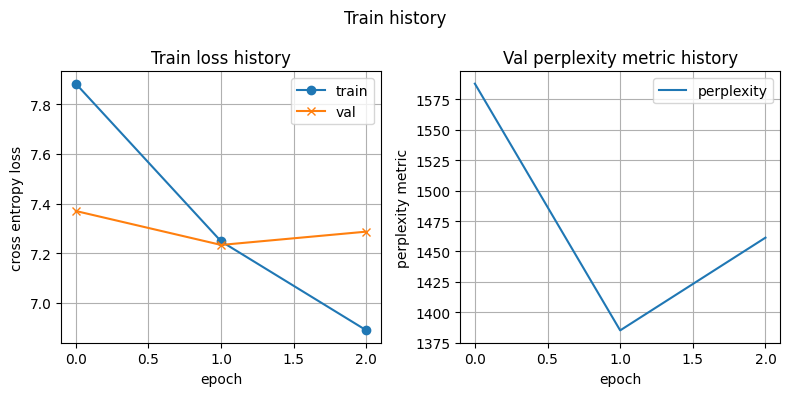

In [111]:
from torch.utils.data import DataLoader

# random
init_random()

# модель 
model_params = {
    'vocab_size': vocab_df.size,
    'emded_dim': 128,
    'hidden_dim': 256,
    'n_layers': 2, 
    'dropout': 0.2, # 0.5
    'model_type': 'lstm'
}

model = NNWikiTextComplete(**model_params)
print(model)

# loss function
criterion = nn.CrossEntropyLoss()

# optimizer
learning_rate = 0.001
optim = torch.optim.AdamW(model.parameters(), lr=learning_rate)

# загрузчик данных
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, collate_fn=collate_fn, shuffle=True) 
val_loader = DataLoader(val_dataset, batch_size=batch_size, collate_fn=collate_fn) 

# цикл обучения
n_epochs = 3
max_iter = -1 # 500 
max_iter_val = -1 # 500

train_loss_history = []
val_loss_history = []
val_ppl_history = []

for epoch in range(n_epochs):
    train_loss = train_model(model, train_loader, optim, criterion, max_iter)
    train_loss_history.append(train_loss)
    
    val_loss, val_ppl = evaluate_model(model, val_loader, criterion, max_iter_val)
    val_loss_history.append(val_loss)
    val_ppl_history.append(val_ppl)

    print(f'epoch:{epoch} - train_loss = {train_loss}, val_loss = {val_loss}, val_ppl = {val_ppl}')

print(f'result - \n\t loss_history = {train_loss_history}, \n\t val_loss_history = {val_loss_history}, \n\t  ppl_history = {val_ppl_history}')
plot_train_history(train_loss_history, val_loss_history, val_ppl_history)

In [112]:
# расчет обучаемых параметров у модели
total_params = sum(p.numel() for p in model.parameters())
print(f"total parameters: {total_params:,}")

total parameters: 12,229,435


In [113]:
# Сохраним модель после обучения
model.save_model(MODELS_PATH / 'model-lstm.pth')

Model saved to data\models\model-lstm.pth


In [114]:
# Восстановим обученную модель 
model = NNWikiTextComplete.load_model(MODELS_PATH / 'model-lstm.pth')
model

NNWikiTextComplete: vocab_size = 29371, emded_dim = 128, hidden_dim = 256, n_layers = 2, dropout = 0.2, model_type = lstm
Model loaded from data\models\model-lstm.pth


NNWikiTextComplete(
  (embed): Embedding(29371, 128, padding_idx=0)
  (model): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=256, out_features=29371, bias=True)
)

#### Оценка на тестовой выборке

In [115]:
# загрузка данных
# test датасет - токенизация налету, т.к. размер меньше
wiki_ds = pd.read_csv(PREPROCESSING_PATH / 'dataset_clean.csv')
test_texts = wiki_ds[wiki_ds['stage'] == 'test']['texts'].tolist()

test_dataset = WikiTextTorchDataset(test_texts, tokenizer)

WikiTextTorchDataset __init()__: texts size = 2891, seq_len = 32, overlap = 16


100%|██████████| 2891/2891 [00:35<00:00, 81.54it/s] 

self.X len = 12206
self.y len = 12206


In [116]:
# оценка модели
batch_size = 64
test_loader = DataLoader(test_dataset, batch_size=batch_size, collate_fn=collate_fn) 

criterion = nn.CrossEntropyLoss()
max_iter_test = -1
test_loss, test_ppl = evaluate_model(model, test_loader, criterion, max_iter_test)
print(f'test_loss = {test_loss}, test_ppl = {test_ppl}')

eval - batch = 64: 100%|██████████| 191/191 [00:13<00:00, 13.91it/s]

test_loss = 7.267192401186958, test_ppl = 1432.5228522790019


##### Визуальное тестирование
- отобразим предсказание модели на небольшой тестовой выборке с выводом топ-10 слов кандидатов

In [117]:
def show_test_samples_prediction(model: NNWikiTextComplete, sample_data: dict):
    """
    Демонстрация работы модели по предсказанию следующего слова в тестовом датасете

    Args:
        model: обученная модель
        sample_data: пачка данных (батч) из DataLoader
    """

    sample_tokens = sample_data['input_tokens']
    sample_lengths = sample_data['input_lengths']
    sample_true_tokens = sample_data['targets']

    logits = model(sample_tokens, sample_lengths)

    criterion = nn.CrossEntropyLoss()

    loss = criterion(logits, sample_true_tokens).item()
    ppl = perplexity_metric(loss)

    print(f'loss = {loss}, ppl = {ppl}')

    probs = torch.softmax(logits, dim=1) 

    # top 10 preditioctions
    top_probs, top_idxs = torch.topk(probs, k=10, dim=1)

    for i in range(len(sample_tokens)):

        top_token = top_idxs[i,0].item()
        top_proba = top_probs[i,0].item()
        pred_top_10_probas = top_probs[i]

        # convert to text
        text = tokenizer.conver_to_words(sample_tokens[i].tolist())
        pred_word = tokenizer.conver_to_words([top_token]).item()
        pred_top_10 = tokenizer.conver_to_words(top_idxs[i].tolist())
        true_words = tokenizer.conver_to_words(sample_true_tokens[i].tolist())

        print(f'{i+1} - text: "{" ".join(text)}"')
        print(f'    true word = "{true_words}"')
        print(f'    pred_word = "{pred_word}" (proba = {top_proba:.2%})')
        print(f'    pred_word_top_10        = {[f"{str(w):<8}" for w in pred_top_10]}')
        print(f'    pred_word_top_10 probas = {[f"{p.item():<8.2%}" for p in pred_top_10_probas]}')

In [120]:
init_random()

# генерируем 10 случайных индексов для выбора текста
test_text_size = 10
sample_idx = np.random.randint(0,1000,test_text_size)

# загружаем пачку данных
test_loader = DataLoader(test_dataset, batch_size=test_text_size, sampler=sample_idx, collate_fn=collate_fn) 
sample_text = next(iter(test_loader))

# вывод предсказаний
print(f'sample_idx = {sample_idx}')
show_test_samples_prediction(model, sample_text)

sample_idx = [836 320 255 817 277  58  16 307 657 187]
loss = 8.419321060180664, ppl = 4533.824216206871
1 - text: "in a practice session for the august 1949 chicago college all star game press accounts at the time noted that the injury will probably keep him out of pro football all"
    true word = "season"
    pred_word = "and" (proba = 6.60%)
    pred_word_top_10        = ['and     ', 'in      ', 'of      ', '<UNK>   ', 'was     ', 'to      ', 'the     ', 's       ', 'on      ', 'as      ']
    pred_word_top_10 probas = ['6.60%   ', '4.46%   ', '3.55%   ', '2.83%   ', '2.69%   ', '2.31%   ', '2.10%   ', '1.65%   ', '1.27%   ', '1.11%   ']
2 - text: "kiss you is an uptempo upbeat power pop song which runs for a duration of 3 04 3 minutes four seconds the track features electronic effects colossal hooks a na na"
    true word = "na"
    pred_word = "the" (proba = 13.69%)
    pred_word_top_10        = ['the     ', 'and     ', 'in      ', 'to      ', 'of      ', '<UNK>   ', 'a       ', 

## Этап 3. Эксперимент: GRU vs LSTM
1. Заменить LSTM на GRU в модели.
2. Обучить GRU-модель с теми же гиперпараметрами.
3. Сравнить perplexity, количество параметров, время на эпоху.

### Обучение модели

NNWikiTextComplete: vocab_size = 29371, emded_dim = 128, hidden_dim = 256, n_layers = 2, dropout = 0.2, model_type = gru
NNWikiTextComplete(
  (embed): Embedding(29371, 128, padding_idx=0)
  (model): GRU(128, 256, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=256, out_features=29371, bias=True)
)


train - batch = 64:  31%|███       | 500/1617 [02:22<05:00,  3.71it/s]

iter:500 - loss = 8.301827430725098


train - batch = 64:  62%|██████▏   | 1000/1617 [04:42<02:47,  3.68it/s]

iter:1000 - loss = 7.306430816650391


...

iter:1000 - loss = 6.967986106872559


train - batch = 64:  93%|█████████▎| 1500/1617 [06:46<00:33,  3.46it/s]

iter:1500 - loss = 6.932621479034424


eval - batch = 64: 100%|██████████| 170/170 [00:09<00:00, 18.12it/s]


epoch:2 - train_loss_avg = 7.289870852810701, val_loss_avg = 7.7491761852713195, val_ppl = 2319.6606566375112
result - 
	 loss_history = [7.979718016634477, 7.535688879759723, 7.289870852810701], 
	 val_loss_history = [7.5417932762819175, 7.577161707597621, 7.7491761852713195], 
	  ppl_history = [np.float64(1885.207693954911), np.float64(1953.077685481026), np.float64(2319.6606566375112)]


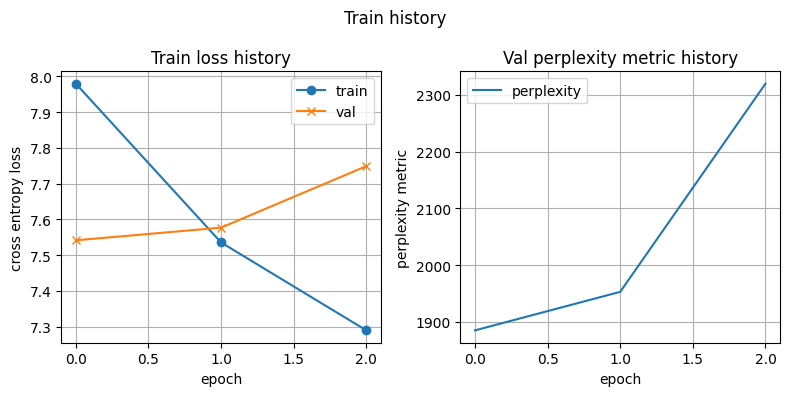

In [121]:
import numpy as np
import torch
from torch.utils.data import DataLoader

# random
init_random()

# модель - параметры аналогичны LSTM, кроме model_type
model_params = {
    'vocab_size': vocab_df.size,
    'emded_dim': 128,
    'hidden_dim': 256,
    'n_layers': 2, 
    'dropout': 0.2, # 0.5
    'model_type': 'gru'
}

model = NNWikiTextComplete(**model_params)
print(model)

# loss function
criterion = nn.CrossEntropyLoss()

# optimizer
learning_rate = 0.001
optim = torch.optim.AdamW(model.parameters(), lr=learning_rate)

# загрузчик данных
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, collate_fn=collate_fn, shuffle=True) 
val_loader = DataLoader(val_dataset, batch_size=batch_size, collate_fn=collate_fn) 

# цикл обучения
n_epochs = 3
max_iter = -1
max_iter_val = -1

train_loss_history = []
val_loss_history = []
val_ppl_history = []

for epoch in range(n_epochs):
    train_loss = train_model(model, train_loader, optim, criterion, max_iter)
    train_loss_history.append(train_loss)
    
    val_loss, val_ppl = evaluate_model(model, val_loader, criterion, max_iter_val)
    val_loss_history.append(val_loss)
    val_ppl_history.append(val_ppl)

    print(f'epoch:{epoch} - train_loss_avg = {train_loss}, val_loss_avg = {val_loss}, val_ppl = {val_ppl}')

print(f'result - \n\t loss_history = {train_loss_history}, \n\t val_loss_history = {val_loss_history}, \n\t  ppl_history = {val_ppl_history}')
plot_train_history(train_loss_history, val_loss_history, val_ppl_history)

In [122]:
# расчет обучаемых параметров у модели
total_params = sum(p.numel() for p in model.parameters())
print(f"total parameters: {total_params:,}")

total parameters: 11,999,035


In [123]:
# Сохраним модель после обучения

model.save_model(MODELS_PATH / 'model-gru.pth')

Model saved to data\models\model-gru.pth


In [124]:
# Восстановим обученную модель 

model = NNWikiTextComplete.load_model(MODELS_PATH / 'model-gru.pth')
model

NNWikiTextComplete: vocab_size = 29371, emded_dim = 128, hidden_dim = 256, n_layers = 2, dropout = 0.2, model_type = gru
Model loaded from data\models\model-gru.pth


NNWikiTextComplete(
  (embed): Embedding(29371, 128, padding_idx=0)
  (model): GRU(128, 256, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=256, out_features=29371, bias=True)
)

### Оценка на тестовой выборке

In [125]:
# test датасет - токенизация налету, т.к. размер меньше
wiki_ds = pd.read_csv(PREPROCESSING_PATH / 'dataset_clean.csv')
test_texts = wiki_ds[wiki_ds['stage'] == 'test']['texts'].tolist()

# формируем тестовый датасет
test_dataset = WikiTextTorchDataset(test_texts, tokenizer)

WikiTextTorchDataset __init()__: texts size = 2891, seq_len = 32, overlap = 16


100%|██████████| 2891/2891 [00:36<00:00, 79.04it/s] 

self.X len = 12206
self.y len = 12206


In [126]:
# запуск предсказаний

batch_size = 64
test_loader = DataLoader(test_dataset, batch_size=batch_size, collate_fn=collate_fn) 

criterion = nn.CrossEntropyLoss()
max_iter_test = -1
test_loss, test_ppl = evaluate_model(model, test_loader, criterion, max_iter_test)
print(f'test_loss = {test_loss}, test_ppl = {test_ppl}')

eval - batch = 64: 100%|██████████| 191/191 [00:10<00:00, 17.66it/s]

test_loss = 7.73014437840247, test_ppl = 2275.9307723164716


#### Визуальное тестирование

In [127]:
init_random()
test_text_size = 10
sample_idx = np.random.randint(0,1000,test_text_size)

test_loader = DataLoader(test_dataset, batch_size=test_text_size, sampler=sample_idx, collate_fn=collate_fn) 
sample_text = next(iter(test_loader))

show_test_samples_prediction(model, sample_text)

loss = 8.672143936157227, ppl = 5838.002246131038
1 - text: "in a practice session for the august 1949 chicago college all star game press accounts at the time noted that the injury will probably keep him out of pro football all"
    true word = "season"
    pred_word = "the" (proba = 7.73%)
    pred_word_top_10        = ['the     ', 'of      ', 'and     ', '<UNK>   ', 'to      ', 'in      ', 'a       ', 'on      ', 'as      ', 'that    ']
    pred_word_top_10 probas = ['7.73%   ', '3.83%   ', '3.04%   ', '2.52%   ', '2.48%   ', '2.19%   ', '2.04%   ', '1.14%   ', '1.12%   ', '1.04%   ']
2 - text: "kiss you is an uptempo upbeat power pop song which runs for a duration of 3 04 3 minutes four seconds the track features electronic effects colossal hooks a na na"
    true word = "na"
    pred_word = "the" (proba = 4.16%)
    pred_word_top_10        = ['the     ', 'of      ', '<UNK>   ', 'and     ', 'to      ', 'that    ', 'on      ', 'in      ', 'a       ', 'it      ']
    pred_word_top_10

### Сравнение

Сравнение показателей обучения моделей LSTM vs GRU

**Обучение и валидация**

| Тип модели | N параметров | Размер батча | N эпох | N итераций обучения| N итерация валидации | Время работы | Val loss | Perplexity 
| --         | --           | --           | --     | --                 | --                   | --           | --       | --         
| LSTM       | 12,229,435   | 64           | 3      | -                  | -                    | 30 м 43 сек  | 7.29     | 1461.36    
| GRU        | 11,999,035   | 64           | 3      | -                  |                      | 23 м 16 сек  | 7.75     | 2319.66    
	
**Оценка на тестовой выборке**

| Тип модели | Размер батча | Время работы | Avg loss  | Perplexity 
| --         | --           | --           | --        | --         
| LSTM       | 64           | 13.7 сек     | 7.27      | 1432.52 
| GRU        | 64           | 10.8 сек     | 7.73      | 2275.93

Выводы:
- время обучения 
    - LSTM требует примерно на 25% больше времени, чем GRU
- ошибка (val loss) 
    - LSTM достиг меньшей ошибки, снизившись с 7.37 до 7.28 за 3 эпохи
    - GRU - c 7.54 до 7.75 - даже выросла на 3-ей эпохи
- метрика perplexity
    - LSTM достиг большей точности, меньше "сомневается в результате", чем GRU - 1461 vs 2319
- таким образом, LSTM побеждает GRU в качестве
- визуальное тестирование предсказаний на текстах показывает, что модели пока могут только предсказывать простые предлоги/союзы
- при этом
    - LSTM требует больше времени/ресурсов на обучение.
    - обе модели начинают переучиваться и на 3-ей эпохи показывают ухудшение метрик валидации, хотя метрики обучения продолжают улучшаться
    - достинутое качество (ppl~ 1500-2300) довольно далеко от реального применения
    - для улучшения качество необходимо рассмотреть дополнительные механизмы
        - перебор гиперпараметров модели (слои, глубина)
        - регуляризация
        - dropout
        - batch_norm
        - управление learning_rate

##  Этап 4. Оценка distilgpt2

1. Загрузить предобученный distilgpt2 и его токенизатор.
2. Вычислить perplexity distilgpt2 на тестовой выборке.
3. Показать примеры предсказаний distilgpt2.

### Инициализация модели и токенизатора

In [128]:
# загрузка модели и токенизатора

from transformers import GPT2LMHeadModel, GPT2TokenizerFast # type: ignore

model_name = 'distilgpt2'
gpt2_tokenizer = GPT2TokenizerFast.from_pretrained(model_name)
print(gpt2_tokenizer)

gpt2_model: GPT2LMHeadModel = GPT2LMHeadModel.from_pretrained(model_name)
print(gpt2_model)

# инициализируем pad_token (не задан по умолчанию)
gpt2_tokenizer.pad_token = gpt2_tokenizer.eos_token

GPT2Tokenizer(name_or_path='distilgpt2', vocab_size=50257, model_max_length=1024, padding_side='right', truncation_side='right', special_tokens={'bos_token': '<|endoftext|>', 'eos_token': '<|endoftext|>', 'unk_token': '<|endoftext|>'}, added_tokens_decoder={
	50256: AddedToken("<|endoftext|>", rstrip=False, lstrip=False, single_word=False, normalized=True, special=True),
})


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-5): 6 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)


### Датасет для модели

Важно - на предобработанном датасете модель gpt2 показывала плохое качество, поэтому используется исходный необработанный датасет

In [129]:
# загрузка словаря
vocab_df = pd.read_csv(PREPROCESSING_PATH / 'vocab.csv')
print(f'vocab_df size = {len(vocab_df)}')

# загрузка подготовленного датасета - не подходит для GPT2
#wiki_ds = pd.read_csv(PREPROCESSING_PATH / 'dataset_clean.csv')

# берем необработанный датасет
wiki_ds = pd.read_csv(PREPROCESSING_PATH / 'dataset.csv')

test_texts = wiki_ds[wiki_ds['stage'] == 'test']['texts'].tolist()
print(f'test_texts len = {len(test_texts)}')

test_texts[0:5]

vocab_df size = 29371
test_texts len = 2891


[' = Robert Boulter = \n',
 ' Robert Boulter is an English film , television and theatre actor . He had a guest @-@ starring role on the television series The Bill in 2000 . This was followed by a starring role in the play Herons written by Simon Stephens , which was performed in 2001 at the Royal Court Theatre . He had a guest role in the television series Judge John Deed in 2002 . In 2004 Boulter landed a role as " Craig " in the episode " Teddy \'s Story " of the television series The Long Firm ; he starred alongside actors Mark Strong and Derek Jacobi . He was cast in the 2005 theatre productions of the Philip Ridley play Mercury Fur , which was performed at the Drum Theatre in Plymouth and the Menier Chocolate Factory in London . He was directed by John Tiffany and starred alongside Ben Whishaw , Shane Zaza , Harry Kent , Fraser Ayres , Sophie Stanton and Dominic Hall . \n',
 ' In 2006 , Boulter starred alongside Whishaw in the play Citizenship written by Mark Ravenhill . He appea

In [130]:
from typing import Dict
import torch
from tqdm import tqdm
from torch.utils.data import Dataset

class WikiTextGPT2Dataset(Dataset):
    """
    Датасет для модели GPT2 - логика аналогична `WikiTextTorchDataset`, 
    только в данном случае подсловный токенизатор - `GPT2TokenizerFast`, 
    который может разбивать слова на несколько токенов (в отличие от пословного токенизатора `WikiTextWordTokenizer`, используемого для RNN моделей)
    """
    
    def __init__(self, texts: list, tokenizer: GPT2TokenizerFast, seq_len=32, overlap=16):
        """
        См. аналогичный `WikiTextTorchDataset`.
        Нарезка цепочек по `seq_len` слов с пересечением скользящим окном на `overlap` слов и токенизация этих цепочек.

        Так как `GPT2TokenizerFast` выполнеяет подсловную токенизацию (BPE), то целевое слово может быть разбито на несколько токенов.
        В таком случае 1-в-1 результат не получится сравнить с собственными моделями и словесным токенизатором.
        Как упрощение в качестве таргета (`y`) используется 1-ый токен из последнего токенизированного слова.
        """
        
        print(f'WikiTextGPT2Dataset __init()__: texts size = {len(texts)}, seq_len = {seq_len}, overlap = {overlap}')

        self.seq_len = seq_len
        self.overlap = overlap

        self.X = []
        self.y = []
        
        for text in tqdm(texts):
            words = text.split()
            # если текст всего из 2-х слов, то разбить его на X и y не получится
            if len(words) > 2:
                # разбиваем на цепочки 
                chunks = split_text_chunks(words, seq_len=seq_len, overlap=overlap)
                
                # соединяем обратно в текст (так нужно для токенизатора GPT2)
                chunks = [" ".join(chunk) for chunk in chunks]
                
                # токенизируем весь текст
                tokens = tokenizer(chunks, padding=False, add_special_tokens=False)['input_ids']
                
                # разделяем на x и y, в y отдаем самый последний токен, который был выделен токенизатором (это может быть и часть слова)
                for ids in tokens:
                     self.X.append(torch.tensor(ids[0:-1]))
                     self.y.append(torch.tensor(ids[-1]))

        print(f'self.X len = {len(self.X)}')
        print(f'self.y len = {len(self.y)}')

    def __len__(self) -> int:
        return len(self.X)

    def __getitem__(self, index) -> Dict[str, torch.Tensor]:
        """
        Return `(X, y)` tuple of tensors
        """
        return {
            'text': self.X[index], 
            'target': self.y[index]
        }

In [131]:
# посмотрим как выглядит пример токенизированных данных
gpt2_test_dataset = WikiTextGPT2Dataset(test_texts, gpt2_tokenizer)

sample_tokenized_text = next(iter(DataLoader(gpt2_test_dataset, batch_size=3, collate_fn=(lambda texts: collate_fn(texts, gpt2_tokenizer.pad_token_id)))))
sample_tokenized_text

WikiTextGPT2Dataset __init()__: texts size = 2891, seq_len = 32, overlap = 16


100%|██████████| 2891/2891 [00:01<00:00, 2108.13it/s]

self.X len = 14579
self.y len = 14579


{'input_tokens': tensor([[   28,  5199,   347,  2852,   353, 50256, 50256, 50256, 50256, 50256,
          50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256,
          50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256,
          50256, 50256, 50256, 50256, 50256],
         [19156,   347,  2852,   353,   318,   281,  3594,  2646,   837,  5581,
            290, 21421,  8674,   764,   679,   550,   257,  8319,  2488,    12,
             31, 20495,  2597,   319,   262,  5581,  2168,   383,  3941,   287,
           4751,   764,   770,   373,  3940],
         [   31,    12,    31, 20495,  2597,   319,   262,  5581,  2168,   383,
           3941,   287,  4751,   764,   770,   373,  3940,   416,   257, 20495,
           2597,   287,   262,   711,  2332,   684,  3194,   416, 11288, 37072,
            837,   543,   373,  6157, 50256]]),
 'input_lengths': tensor([ 5, 35, 34]),
 'targets': tensor([796, 416, 287])}

### Предсказание и оценка

In [132]:
import numpy as np
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm

# random
init_random()

# device - CPU or GPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'    

gpt2_model.to(device=device) # type: ignore
print(gpt2_model)

# loss function
criterion = nn.CrossEntropyLoss()

# loader
pad_token = gpt2_tokenizer.pad_token_id
batch_size = 64
gpt2_loader = DataLoader(gpt2_test_dataset, batch_size=batch_size, collate_fn=(lambda texts: collate_fn(texts, pad_token)))

# eval loop
total_loss = 0
max_iter = -1 
n_iter = 0

gpt2_model.eval()
for batch in tqdm(gpt2_loader, desc=f'eval - batch = {gpt2_loader.batch_size}'):
    n_iter += 1
    #print(f'--------------')
    
    x = batch['input_tokens'].to(device)
    x_length = batch['input_lengths'].to(device)
    y = batch['targets'].to(device)

    # predict
    with torch.no_grad(): 
        output = gpt2_model(x)
    
    #print(f'output = {output}')

    logits = output.logits # shape: [batch, seq_len, vocab_size]
    #print(f'logits = {logits}')

    # определяем позицию последнего значимого токена (исключаем паддинги)
    last_token_indices = x_length - 1 
    # извлекаем логиты именно для этого токена
    last_token_logits = logits[torch.arange(x.size(0)), last_token_indices, :] # shape: [batch, vocab_size]
    #print(f'last_token_logits = {last_token_logits}')

    # calc loss
    loss = criterion(last_token_logits, y)
    total_loss += loss.item()    

    if n_iter == max_iter:
        break

avg_loss = total_loss / n_iter
ppl_metric = perplexity_metric(avg_loss)

print(f'result - avg_loss = {avg_loss}, ppl_metric = {ppl_metric}')

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-5): 6 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)


eval - batch = 64: 100%|██████████| 228/228 [11:39<00:00,  3.07s/it]

result - avg_loss = 4.021858433882396, ppl_metric = 55.8047188983511


In [134]:
# расчет обучаемых параметров у модели
total_params = sum(p.numel() for p in gpt2_model.parameters())
print(f"total parameters: {total_params:,}")

total parameters: 81,912,576


### Визуальная проверка

In [135]:
init_random()
test_text_size = 10

# случайные индексы текстов
sample_idx = np.random.randint(0,1000,test_text_size)

# загрузка из gpt2-датасета
pad_token = gpt2_tokenizer.pad_token_id
test_loader = DataLoader(gpt2_test_dataset, batch_size=test_text_size, sampler=sample_idx, collate_fn=(lambda texts: collate_fn(texts, pad_token)))
sample_text = next(iter(test_loader))

# предсказание модели    
x = sample_text['input_tokens']
x_length = sample_text['input_lengths']
y = sample_text['targets']

with torch.no_grad(): 
    output = gpt2_model(x)
logits = output.logits # shape: [batch, seq_len, vocab_size]

# определяем позицию последнего значимого токена (исключаем паддинги)
last_token_indices = x_length - 1 
# извлекаем логиты именно для этого токена
last_token_logits = logits[torch.arange(test_text_size), last_token_indices, :] # shape: [batch, vocab_size]

# вероятности токенов
probs = torch.softmax(last_token_logits, dim=1) 

# топ 10 предсказаний
top_probs, top_idxs = torch.topk(probs, k=10, dim=1)

# отображение результатов в текстовом виде
for i in range(test_text_size):
    top_token = top_idxs[i,0].item()
    top_proba = top_probs[i,0].item()

    # convert to text
    real_len = x_length[i].item()
    text = gpt2_tokenizer.decode(x[i][:real_len])
    
    pred_word = gpt2_tokenizer.decode([top_token])
    true_word = gpt2_tokenizer.decode(y[i])

    pred_top_10 = [gpt2_tokenizer.decode(id) for id in top_idxs[i]]
    pred_top_10_probas = top_probs[i]

    print(f'{i+1}/{sample_idx[i]} - text: "{text}"')
    print(f'    true word = "{true_word}"')
    print(f'    pred_word = "{pred_word}" (proba = {top_proba:.2%})')
    print(f'    pred_word_top_10        = {[f"{str(w):<8}" for w in pred_top_10]}')
    print(f'    pred_word_top_10 probas = {[f"{p.item():<8.2%}" for p in pred_top_10_probas]}')
  

1/836 - text: "attacking Pearl Harbor , and returned six days later . On 11 March 1942 Ise and Hyūga sortied from their anchorage at Hashirajima to join the unsuccessful search for the American"
    true word = " carrier"
    pred_word = " submarine" (proba = 8.03%)
    pred_word_top_10        = [' submarine', ' ship   ', ' flag   ', ' destroyer', ' aircraft', ' carrier', '-       ', ' Navy   ', ' bomber ', ' fleet  ']
    pred_word_top_10 probas = ['8.03%   ', '4.95%   ', '4.92%   ', '3.76%   ', '2.57%   ', '2.02%   ', '1.77%   ', '1.58%   ', '1.14%   ', '1.13%   ']
2/320 - text: "] was the very best poet in history and praised Shào Chuán 's commentary for its simplicity and readability , while he criticized old commentaries during the Yuan Dynasty were too unfathom"
    true word = "able"
    pred_word = "able" (proba = 81.39%)
    pred_word_top_10        = ['able    ', 'ably    ', 'ingly   ', 'ables   ', 'table   ', 'ible    ', 'ly      ', 'less    ', 'ability ', 'ful     ']
    pre

### Выводы
- модель `distilgp2` демонстрирует достаточно хорошую метрику perplexity ~ 55.8 (на всей тестовой выборке), но и по времени это заняло 11 минут (vs 13 сек у LSTM).
- слова на случайных текстах в предсказании подбираются с большим разнообразием и разной степенью уверенности, есть и совпадния

## Этап 5. Сравнение и выводы
- Подготовить сводные итоги по результатам всех моделей в таблице: модель, число параметров, val perplexity, test perplexity, время на эпоху.
- Покажите примеры предсказаний всех моделей на одних и тех же контекстах (5–10 примеров).
- Сделайте выводы: какая модель лучше и почему. Дайте рекомендации для продакт-менеджера.

### Сравнение показателей и результатов моделей LSTM vs GRU vs DistilGPT-2

- так как модель `DisitlGPT-2` уже предобучена, сравниваются только значения оценки модели на тестовой выборке
- сравить в лоб кастомные модели (LSTM и GRU) с GPT-2 не получилось, так как для GPT-2 нужно подавать необработанный текст, и с особой логикой разбиения на цепочки для токенизации - не по словам, а по токенам
    - на очищенном датасете, на котором обучались LSTM/GRU, а также при разбиении по словам, а не по токенам, GPT2 выдавала очень плохой результат (почти случайный)
    - исходя из того, что для GPT2 критично именно наличие оригинального текста, близкого к тому, на котором модель обучалась, сравнение выполнено по косвенным признакам

**Обучение и валидация**

| Тип модели | N параметров | Размер батча | N эпох | N итераций обучения| N итерация валидации | Время работы | Val loss | Perplexity 
| --         | --           | --           | --     | --                 | --                   | --           | --       | --         
| LSTM       | 12,229,435   | 64           | 3      | -                  | -                    | 30 м 43 сек  | 7.29     | 1461.36    
| GRU        | 11,999,035   | 64           | 3      | -                  |                      | 23 м 16 сек  | 7.75     | 2319.66    
| DistilGPT2 | 81,912,576   | -            | -      | -                  | -                    | -            | -        | - 

**Оценка на тестовой выборке**

| Тип модели | Размер батча | Время работы | Avg loss  | Perplexity 
| --         | --           | --           | --        | --         
| LSTM       | 64           | 13.7 сек     | 7.27      | 1432.52 
| GRU        | 64           | 10.8 сек     | 7.73      | 2275.93
| DistilGPT2 | 64           | 11.39 мин    | 4.02      | 55.80

### Демонстрация работы на тестовой подвыборке

Пример предсказания на реальном тексте с наиболее вероятными кандидатами предсказания (полный список из 10 примеров приведен в соответсвующем разделе):

- `DistilGPT2` - 2 примера - видно что модель точно определяет даже части слов (из-за разбиения на токены, а не по словам):
``` txt
1/836 - text: "attacking Pearl Harbor , and returned six days later . On 11 March 1942 Ise and Hyūga sortied from their anchorage at Hashirajima to join the unsuccessful search for the American"
    true word = " carrier"
    pred_word = " submarine" (proba = 8.03%)
    pred_word_top_10        = [' submarine', ' ship   ', ' flag   ', ' destroyer', ' aircraft', ' carrier', '-       ', ' Navy   ', ' bomber ', ' fleet  ']
    pred_word_top_10 probas = ['8.03%   ', '4.95%   ', '4.92%   ', '3.76%   ', '2.57%   ', '2.02%   ', '1.77%   ', '1.58%   ', '1.14%   ', '1.13%   ']
2/320 - text: "] was the very best poet in history and praised Shào Chuán 's commentary for its simplicity and readability , while he criticized old commentaries during the Yuan Dynasty were too unfathom"
    true word = "able"
    pred_word = "able" (proba = 81.39%)
    pred_word_top_10        = ['able    ', 'ably    ', 'ingly   ', 'ables   ', 'table   ', 'ible    ', 'ly      ', 'less    ', 'ability ', 'ful     ']
    pred_word_top_10 probas = ['81.39%  ', '18.54%  ', '0.02%   ', '0.01%   ', '0.01%   ', '0.00%   ', '0.00%   ', '0.00%   ', '0.00%   ', '0.00%   ']    
```
------------
- `GRU` - модель в основном выучила предлоги и союзы
``` txt
1 - text: "in a practice session for the august 1949 chicago college all star game press accounts at the time noted that the injury will probably keep him out of pro football all"
    true word = "season"
    pred_word = "the" (proba = 7.73%)
    pred_word_top_10        = ['the     ', 'of      ', 'and     ', '<UNK>   ', 'to      ', 'in      ', 'a       ', 'on      ', 'as      ', 'that    ']
    pred_word_top_10 probas = ['7.73%   ', '3.83%   ', '3.04%   ', '2.52%   ', '2.48%   ', '2.19%   ', '2.04%   ', '1.14%   ', '1.12%   ', '1.04%   ']
2 - text: "kiss you is an uptempo upbeat power pop song which runs for a duration of 3 04 3 minutes four seconds the track features electronic effects colossal hooks a na na"
    true word = "na"
    pred_word = "the" (proba = 4.16%)
    pred_word_top_10        = ['the     ', 'of      ', '<UNK>   ', 'and     ', 'to      ', 'that    ', 'on      ', 'in      ', 'a       ', 'it      ']
    pred_word_top_10 probas = ['4.16%   ', '3.69%   ', '3.02%   ', '2.97%   ', '2.66%   ', '1.46%   ', '1.43%   ', '1.20%   ', '1.17%   ', '1.02%   ']
```
------------
- `LSTM` - модель в основном выучила предлоги и союзы
``` txt
1 - text: "in a practice session for the august 1949 chicago college all star game press accounts at the time noted that the injury will probably keep him out of pro football all"
    true word = "season"
    pred_word = "and" (proba = 6.60%)
    pred_word_top_10        = ['and     ', 'in      ', 'of      ', '<UNK>   ', 'was     ', 'to      ', 'the     ', 's       ', 'on      ', 'as      ']
    pred_word_top_10 probas = ['6.60%   ', '4.46%   ', '3.55%   ', '2.83%   ', '2.69%   ', '2.31%   ', '2.10%   ', '1.65%   ', '1.27%   ', '1.11%   ']
2 - text: "kiss you is an uptempo upbeat power pop song which runs for a duration of 3 04 3 minutes four seconds the track features electronic effects colossal hooks a na na"
    true word = "na"
    pred_word = "the" (proba = 13.69%)
    pred_word_top_10        = ['the     ', 'and     ', 'in      ', 'to      ', 'of      ', '<UNK>   ', 'a       ', 'was     ', 'on      ', 'as      ']
    pred_word_top_10 probas = ['13.69%  ', '6.11%   ', '5.41%   ', '4.24%   ', '3.99%   ', '3.08%   ', '2.66%   ', '2.42%   ', '2.22%   ', '1.82%   ']
```

Попробуем выполнить предскание всеми моделями на выдуманном тексте, раз уж датасеты получились несовместимые

In [136]:
# случайный текст
sample_text = "In science, the natural world refers to all the physical, chemical, and biological components of the universe — including"
sample_answer = "atoms"
rest_of_text = "atoms, forces, ecosystems, and planets—that occur and evolve independently of human creation"

In [137]:
# модель GPT2

sample_x = gpt2_tokenizer(sample_text, return_tensors='pt')['input_ids']
sample_y = gpt2_tokenizer(sample_answer, return_tensors='pt')['input_ids'][0][0]

gpt2_model.eval()
with torch.no_grad(): 
    output = gpt2_model(sample_x)

logits = output.logits 
last_token_logits = logits[0, -1, :] 

criterion = nn.CrossEntropyLoss()

loss = criterion(last_token_logits, sample_y).item()
ppl = perplexity_metric(loss)

print(f'loss = {loss}, ppl = {ppl}')

proba = torch.softmax(last_token_logits, dim=-1) 
top_proba, top_idxs = torch.topk(proba, k=10) 

pred_token = top_idxs[0]
pred_word = gpt2_tokenizer.decode(pred_token)
pred_words = [gpt2_tokenizer.decode(token) for token in top_idxs]

print(f'text = {gpt2_tokenizer.decode(sample_x)}')
print(f'true word = {gpt2_tokenizer.decode(sample_y)}')
print(f'pred_word = {pred_word}')
print(f'pred_words = {pred_words}')
print(f'top_proba = {top_proba}')

loss = 16.807645797729492, ppl = 19928188.555748828
text = ['In science, the natural world refers to all the physical, chemical, and biological components of the universe — including']
true word = at
pred_word =  the
pred_words = [' the', ' our', ' all', ',', ' life', ' those', ' matter', ' everything', ' stars', ' physical']
top_proba = tensor([0.3103, 0.0828, 0.0593, 0.0523, 0.0309, 0.0245, 0.0214, 0.0181, 0.0137,
        0.0088])


In [138]:
# модель GRU 

sample_text_rnn = preprocess_text(sample_text)

sample_x = torch.tensor([tokenizer.tokenize(sample_text_rnn.split())])
sample_y = torch.tensor(tokenizer.tokenize([sample_answer]))

sample_input_rnn = {
    'input_tokens': sample_x,
    'input_lengths': torch.tensor([len(sample_x)]),
    'targets': sample_y,
}

model = NNWikiTextComplete.load_model(MODELS_PATH / 'model-gru.pth')

show_test_samples_prediction(model, sample_input_rnn)

NNWikiTextComplete: vocab_size = 29371, emded_dim = 128, hidden_dim = 256, n_layers = 2, dropout = 0.2, model_type = gru
Model loaded from data\models\model-gru.pth
loss = 10.382569313049316, ppl = 32291.82279924737
1 - text: "in science the natural world refers to all the physical chemical and biological components of the universe including"
    true word = "atoms"
    pred_word = "<UNK>" (proba = 0.63%)
    pred_word_top_10        = ['<UNK>   ', 'the     ', 'season  ', 'ii      ', '2007    ', 'time    ', 'and     ', 'culture ', 'of      ', 'career  ']
    pred_word_top_10 probas = ['0.63%   ', '0.22%   ', '0.14%   ', '0.13%   ', '0.13%   ', '0.12%   ', '0.12%   ', '0.12%   ', '0.11%   ', '0.11%   ']


In [139]:
# модель LSTM 

sample_text_rnn = preprocess_text(sample_text)

sample_x = torch.tensor([tokenizer.tokenize(sample_text_rnn.split())])
sample_y = torch.tensor(tokenizer.tokenize([sample_answer]))

sample_input_rnn = {
    'input_tokens': sample_x,
    'input_lengths': torch.tensor([len(sample_x)]),
    'targets': sample_y,
}

model = NNWikiTextComplete.load_model(MODELS_PATH / 'model-lstm.pth')

show_test_samples_prediction(model, sample_input_rnn)

NNWikiTextComplete: vocab_size = 29371, emded_dim = 128, hidden_dim = 256, n_layers = 2, dropout = 0.2, model_type = lstm
Model loaded from data\models\model-lstm.pth
loss = 11.825627326965332, ppl = 136711.38816575962
1 - text: "in science the natural world refers to all the physical chemical and biological components of the universe including"
    true word = "atoms"
    pred_word = "<UNK>" (proba = 2.76%)
    pred_word_top_10        = ['<UNK>   ', 'writing ', 'construction', 'development', 'culture ', 'reception', 'death   ', 'legacy  ', 'release ', 'war     ']
    pred_word_top_10 probas = ['2.76%   ', '0.71%   ', '0.67%   ', '0.58%   ', '0.54%   ', '0.50%   ', '0.47%   ', '0.45%   ', '0.44%   ', '0.44%   ']


Результат:
- ни одна из моделей не угадала верное слово
- при этом GPT2 уверена на 31% в своем прогнозе, и выдает прогнозы довольно близких по смыслу слов
- LSTM/GRU не уверены в своих прогнозах, обучились только на предлогах и союзах

### Выводы
- модель DistilGPT2 выдает уверенные предсказания с небольшой ошибкой, при этом требует почти в 8 раз больше параметров - 80 млн vs 12 млн
- время генерации DistilGPT2 почти в 60 раз больше, чем простые модели
- кастомные RNN модели требуют дальнейшей оптимизации и поиска гиперпараметров
- рекомендации 
    - рассмотреть разные варианты по работе с редкими словами
    - рассмотреть разные варианта разбиения текста
    - рассмотреть варианты регуляризации и оптимизации гиперпараметров в RNN-моделях